# 01 - Exploratory analysis and cleaning

**Part 1** analyses the raw data (variables, target distribution, invalid and duplicated molecules). **Part 2** cleans it and saves the result to `data/processed/` so the next notebooks can load it directly.

## Part 1 - Analysis of the raw data

In [1]:
import pandas as pd
df = pd.read_csv('../data/raw/delaney-processed.csv',usecols=['smiles', 'measured log solubility in mols per litre'])
df

,measured log solubility in mols per litre,smiles
0,-0.770,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,-3.300,Cc1occc1C(=O)Nc2ccccc2
2,-2.060,CC(C)=CCCC(C)=CC(=O)
3,-7.870,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43
4,-1.330,c1ccsc1
...,...,...
1123,-1.710,FC(F)(F)C(Cl)Br
1124,0.106,CNC(=O)ON=C(SC)C(=O)N(C)C
1125,-3.091,CCSCCSP(=S)(OC)OC
1126,-3.180,CCC(C)C


We only need these 2 columns, but the original dataset has many others.
Right now the dataset has 1128 rows and 2 columns.
Let's check whether they have null values.

In [2]:
df.isnull().sum()

measured log solubility in mols per litre    0
smiles                                       0
dtype: int64

### Target variable

In [3]:
df['measured log solubility in mols per litre'].describe()

count    1128.000000
mean       -3.050102
std         2.096441
min       -11.600000
25%        -4.317500
50%        -2.860000
75%        -1.600000
max         1.580000
Name: measured log solubility in mols per litre, dtype: float64

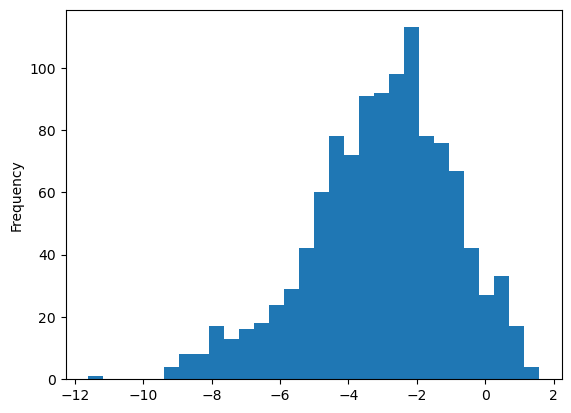

In [4]:
import matplotlib.pyplot as plt 
df['measured log solubility in mols per litre'].plot(kind="hist",bins=30)
plt.show()

<Axes: >

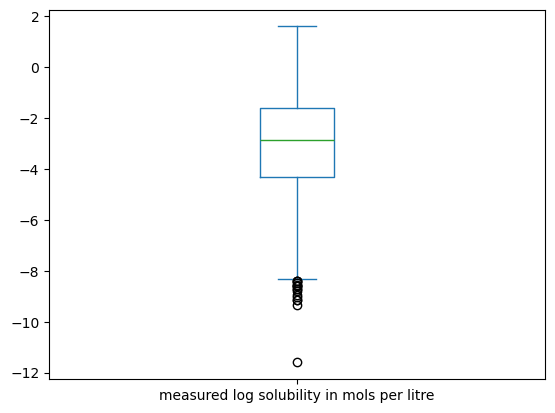

In [5]:
df['measured log solubility in mols per litre'].plot(kind="box")


In [6]:
df[df['measured log solubility in mols per litre'] < -10]

,measured log solubility in mols per litre,smiles
603,-11.6,Clc1c(Cl)c(Cl)c(c(Cl)c1Cl)c2c(Cl)c(Cl)c(Cl)c(C...


In [7]:
df[df['measured log solubility in mols per litre'] < -8.3]

,measured log solubility in mols per litre,smiles
54,-8.600,Clc1cccc(c1Cl)c2c(Cl)c(Cl)cc(Cl)c2Cl
60,-9.150,Clc1cc(Cl)c(Cl)c(c1Cl)c2c(Cl)c(Cl)cc(Cl)c2Cl
181,-8.600,CCOc1ccc(cc1)C(C)(C)COCc3cccc(Oc2ccccc2)c3
220,-8.804,c1cc2cccc3c4cccc5cccc(c(c1)c23)c54
272,-8.402,CC1(C)C(C=C(Br)Br)C1C(=O)OC(C#N)c2cccc(Oc3cccc...
297,-9.160,Clc1cc(c(Cl)c(Cl)c1Cl)c2cc(Cl)c(Cl)c(Cl)c2Cl
299,-8.334,CCCCCCCCCCCCCCCCCCCCCCCCCC
497,-8.490,c1ccc2cc3c4cccc5cccc(c3cc2c1)c45
603,-11.600,Clc1c(Cl)c(Cl)c(c(Cl)c1Cl)c2c(Cl)c(Cl)c(Cl)c(C...
637,-8.699,c1ccc2c(c1)cc3ccc4cccc5ccc2c3c45


The molecules flagged above were investigated, and they are not outliers: they just have very low solubility, so we will keep them in the dataset.
This also gives us a simple insight into the distribution. If we later split these molecules into train and test sets, the algorithm will probably learn that when it sees Cl, Br, or a long carbon chain, the solubility is low. So we have to be careful with that.
We might also guess that molecules with high solubility will get less accurate predictions, because the model will have fewer examples to learn from. We will check that in the next notebooks.

### Molecules: invalid SMILES

In [8]:
from rdkit import Chem


def find_invalid_smiles(smiles):
    """Return the SMILES that RDKit cannot parse (MolFromSmiles returns None)."""
    return smiles[smiles.apply(lambda s: Chem.MolFromSmiles(s) is None)]

In [9]:
invalid = find_invalid_smiles(df['smiles'])
print(f'Invalid SMILES: {len(invalid)}')
invalid

Invalid SMILES: 0


Series([], Name: smiles, dtype: object)

### Molecules: duplicates

Let's check for duplicates.

We have to check for duplicated SMILES. Comparing the raw SMILES strings is the wrong way to do it, because different SMILES can describe the same molecule, and we would treat that molecule as two different ones.

In [10]:
def canonicalize(smiles):
    """Convert a SMILES to its RDKit canonical form."""
    return Chem.MolToSmiles(Chem.MolFromSmiles(smiles))

In [11]:
df['canonical_smiles'] = df['smiles'].apply(canonicalize)
df

,measured log solubility in mols per litre,smiles,canonical_smiles
0,-0.770,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...
1,-3.300,Cc1occc1C(=O)Nc2ccccc2,Cc1occc1C(=O)Nc1ccccc1
2,-2.060,CC(C)=CCCC(C)=CC(=O),CC(C)=CCCC(C)=CC=O
3,-7.870,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,c1ccc2c(c1)ccc1c2ccc2c3ccccc3ccc21
4,-1.330,c1ccsc1,c1ccsc1
...,...,...,...
1123,-1.710,FC(F)(F)C(Cl)Br,FC(F)(F)C(Cl)Br
1124,0.106,CNC(=O)ON=C(SC)C(=O)N(C)C,CNC(=O)ON=C(SC)C(=O)N(C)C
1125,-3.091,CCSCCSP(=S)(OC)OC,CCSCCSP(=S)(OC)OC
1126,-3.180,CCC(C)C,CCC(C)C


We can check for duplicates now:

In [12]:
df['canonical_smiles'].duplicated().sum()

np.int64(11)

In [13]:
g = df.groupby("canonical_smiles")["measured log solubility in mols per litre"]
conflitos = g.agg(["count", "min", "max"])
conflitos = conflitos[conflitos["count"] > 1]
conflitos["amplitude"] = conflitos["max"] - conflitos["min"]
print(conflitos.sort_values("amplitude", ascending=False))

                                         count    min    max  amplitude
canonical_smiles                                                       
OCC(O)C(O)C(O)C(O)CO                         2  0.060  1.090      1.030
CC12CCC3C(CCC4CC(O)CCC43C)C1CCC2=O           2 -4.402 -4.160      0.242
CCC1(CCC(C)C)C(=O)NC(=O)NC1=O                2 -2.658 -2.468      0.190
CC12CCC(CC1)C(C)(C)O2                        2 -1.740 -1.640      0.100
CCC1(C(C)C)C(=O)NC(=O)NC1=O                  2 -2.210 -2.148      0.062
Cc1ncc([N+](=O)[O-])n1CCO                    2 -1.260 -1.220      0.040
Brc1ccc2ccccc2c1                             2 -4.400 -4.400      0.000
CCOP(=S)(OCC)SC(CCl)N1C(=O)c2ccccc2C1=O      2 -6.340 -6.340      0.000
CCC1(c2ccccc2)C(=O)NC(=O)NC1=O               2 -2.322 -2.322      0.000
COc1ccccc1O                                  2 -1.960 -1.960      0.000
Clc1ccc(C(c2ccc(Cl)cc2)C(Cl)Cl)cc1           2 -7.200 -7.200      0.000


In [14]:
df["canonical_smiles"].str.contains(r"\.").sum()

np.int64(0)

## Part 2 - Cleaning

We have 11 duplicated SMILES in the dataframe, so we have to drop them to avoid introducing bias.

In [15]:
def drop_duplicate_molecules(df):
    """Keep the first row of each molecule (same canonical SMILES)."""
    return df.drop_duplicates(subset='canonical_smiles')

In [16]:
df = drop_duplicate_molecules(df)
df

,measured log solubility in mols per litre,smiles,canonical_smiles
0,-0.770,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...
1,-3.300,Cc1occc1C(=O)Nc2ccccc2,Cc1occc1C(=O)Nc1ccccc1
2,-2.060,CC(C)=CCCC(C)=CC(=O),CC(C)=CCCC(C)=CC=O
3,-7.870,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,c1ccc2c(c1)ccc1c2ccc2c3ccccc3ccc21
4,-1.330,c1ccsc1,c1ccsc1
...,...,...,...
1123,-1.710,FC(F)(F)C(Cl)Br,FC(F)(F)C(Cl)Br
1124,0.106,CNC(=O)ON=C(SC)C(=O)N(C)C,CNC(=O)ON=C(SC)C(=O)N(C)C
1125,-3.091,CCSCCSP(=S)(OC)OC,CCSCCSP(=S)(OC)OC
1126,-3.180,CCC(C)C,CCC(C)C


Checks after cleaning:

In [17]:
df['canonical_smiles'].duplicated().sum()

np.int64(0)

In [18]:
df.isnull().sum()

measured log solubility in mols per litre    0
smiles                                       0
canonical_smiles                             0
dtype: int64

In [19]:
df.describe()

,measured log solubility in mols per litre
count,1117.000000
mean,-3.050291
std,2.094710
min,-11.600000
25%,-4.310000
50%,-2.863000
75%,-1.600000
max,1.580000


### Save the clean dataset

In [20]:
from pathlib import Path


def save_clean_dataset(df, path):
    """Save canonical SMILES + target to a CSV, creating the folder if needed."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    df[['canonical_smiles', 'measured log solubility in mols per litre']].to_csv(path, index=False)
    print(f'Saved {len(df)} rows to {path}')

In [21]:
save_clean_dataset(df, '../data/processed/solubility_clean.csv')

Saved 1117 rows to ../data/processed/solubility_clean.csv
